<a href="https://colab.research.google.com/github/houmanhaghi/Golden-mind/blob/AI-Estimator/gold3n_mind.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Pursose**


combination of
  * Buying Au Formula
  * AI Estimation Market

## Buying Au Formula

## AI Estimation Market

In [41]:
import requests
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from persiantools.jdatetime import JalaliDate

In [43]:
url = "https://api.navasan.tech/ohlcSearch/?api_key=freerPVwKRSCRE1qK2YztQ03toKrnDte&item=18ayar&start=1395-01-01&end=1403-09-07"
# response = requests.get(url)
data = response.json()

In [44]:
original_data = data.copy()

In [47]:
df = pd.DataFrame(data)
df = df.drop(columns=['timestamp'])
df = df.drop_duplicates(subset='date', keep='first')
df = df.reset_index(drop=True)
df = df.sort_values(by='date')

In [81]:
df['gregorian_date'] = df['date'].apply(lambda x: JalaliDate(int(x[:4]), int(x[5:7]), int(x[8:10])).to_gregorian())
df['gregorian_date'] = pd.to_datetime(df['gregorian_date'])

In [83]:
df.tail()

,date,open,high,low,close,gregorian_date
1967,1403-09-03,4518910,4703820,4518910,4663880,2024-11-23
1968,1403-09-04,4663880,4676120,4521220,4563230,2024-11-24
1969,1403-09-05,4563230,4567620,4466970,4473430,2024-11-25
1970,1403-09-06,4473430,4503210,4440880,4464430,2024-11-26
1971,1403-09-07,4464430,4521450,4464430,4508060,2024-11-27


In [84]:
df.to_csv(f"gold-grm18ayar-iran?start={str(df[df.index==0]['date'])}&end={str(df[df.index==max(df.index)]['date'])}.csv", index=False)

In [89]:
train_data = df[df['date'] < '1402-07-07'][['gregorian_date','close']]
test_data  = df[df['date'] >='1402-07-07'][['gregorian_date','close']]

In [98]:
train_data['gregorian_date'] = pd.to_datetime(train_data['gregorian_date'], errors='coerce')
test_data['gregorian_date'] = pd.to_datetime(test_data['gregorian_date'], errors='coerce')

In [100]:
train_data = train_data.dropna(subset=['gregorian_date'])
test_data = test_data.dropna(subset=['gregorian_date'])

In [104]:
train_data['close'] = pd.to_numeric(train_data['close'], errors='coerce')
test_data['close'] = pd.to_numeric(test_data['close'], errors='coerce')

In [106]:
train_data = train_data.dropna(subset=['close'])
test_data = test_data.dropna(subset=['close'])

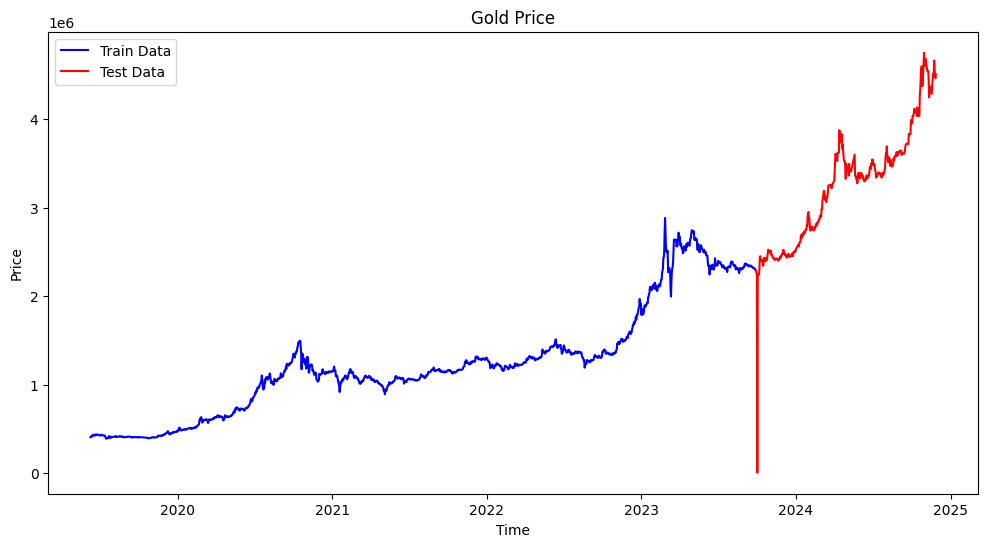

In [107]:
# Plotting
plt.figure(figsize=(12, 6))

# Plot train data using the 'gregorian_date' and 'close' column
plt.plot(train_data['gregorian_date'],
         train_data['close'],  # Assuming 'close' is the column you want to plot
         label='Train Data', color='blue')

# Plot test data using the 'gregorian_date' and 'close' column
plt.plot(test_data['gregorian_date'],
         test_data['close'],
         label='Test Data', color='red')

# Set labels and title
plt.xlabel('Time')
plt.ylabel('Price')
plt.title('Gold Price')
plt.legend()

# Show the plot
plt.show()